## Assignment no 16

## Anime Recommendation System using Cosine Similarity

Import Required Libraries

In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data preprocessing
from sklearn.preprocessing import MinMaxScaler
from sklearn.feature_extraction.text import TfidfVectorizer

# Cosine similarity
from sklearn.metrics.pairwise import cosine_similarity

# Ignore warnings
import warnings
warnings.filterwarnings('ignore')

Load the Dataset

In [2]:
# Load dataset
df = pd.read_csv("anime.csv")

# Display first five records
display(df.head())

# Display last five records
display(df.tail())

# Dataset dimensions
print("Dataset Shape:", df.shape)

# Column names
print("\nColumns:")
print(df.columns)

,anime_id,name,genre,type,episodes,rating,members
0,32281,Kimi no Na wa.,"Drama, Romance, School, Supernatural",Movie,1,9.37,200630
1,5114,Fullmetal Alchemist: Brotherhood,"Action, Adventure, Drama, Fantasy, Magic, Mili...",TV,64,9.26,793665
2,28977,Gintama°,"Action, Comedy, Historical, Parody, Samurai, S...",TV,51,9.25,114262
3,9253,Steins;Gate,"Sci-Fi, Thriller",TV,24,9.17,673572
4,9969,Gintama&#039;,"Action, Comedy, Historical, Parody, Samurai, S...",TV,51,9.16,151266


,anime_id,name,genre,type,episodes,rating,members
12289,9316,Toushindai My Lover: Minami tai Mecha-Minami,Hentai,OVA,1,4.15,211
12290,5543,Under World,Hentai,OVA,1,4.28,183
12291,5621,Violence Gekiga David no Hoshi,Hentai,OVA,4,4.88,219
12292,6133,Violence Gekiga Shin David no Hoshi: Inma Dens...,Hentai,OVA,1,4.98,175
12293,26081,Yasuji no Pornorama: Yacchimae!!,Hentai,Movie,1,5.46,142


Dataset Shape: (12294, 7)

Columns:
Index(['anime_id', 'name', 'genre', 'type', 'episodes', 'rating', 'members'], dtype='object')


Exploratory Data Analysis (EDA)

In [4]:
# Dataset information
df.info()

# Statistical summary
display(df.describe(include='all'))

# Count missing values
print(df.isnull().sum())

# Missing value percentage
missing_percentage = (df.isnull().sum() / len(df)) * 100

display(missing_percentage)

# Count duplicate rows
print("Duplicate Rows:", df.duplicated().sum())

# Remove duplicate rows
df.drop_duplicates(inplace=True)



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12294 entries, 0 to 12293
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   anime_id  12294 non-null  int64  
 1   name      12294 non-null  object 
 2   genre     12232 non-null  object 
 3   type      12269 non-null  object 
 4   episodes  12294 non-null  object 
 5   rating    12064 non-null  float64
 6   members   12294 non-null  int64  
dtypes: float64(1), int64(2), object(4)
memory usage: 672.5+ KB


,anime_id,name,genre,type,episodes,rating,members
count,12294.000000,12294,12232,12269,12294,12064.000000,1.229400e+04
unique,NaN,12292,3264,6,187,NaN,NaN
top,NaN,Shi Wan Ge Leng Xiaohua,Hentai,TV,1,NaN,NaN
freq,NaN,2,823,3787,5677,NaN,NaN
mean,14058.221653,NaN,NaN,NaN,NaN,6.473902,1.807134e+04
std,11455.294701,NaN,NaN,NaN,NaN,1.026746,5.482068e+04
min,1.000000,NaN,NaN,NaN,NaN,1.670000,5.000000e+00
25%,3484.250000,NaN,NaN,NaN,NaN,5.880000,2.250000e+02
50%,10260.500000,NaN,NaN,NaN,NaN,6.570000,1.550000e+03
75%,24794.500000,NaN,NaN,NaN,NaN,7.180000,9.437000e+03


anime_id      0
name          0
genre        62
type         25
episodes      0
rating      230
members       0
dtype: int64


anime_id    0.000000
name        0.000000
genre       0.504311
type        0.203351
episodes    0.000000
rating      1.870831
members     0.000000
dtype: float64

Duplicate Rows: 0


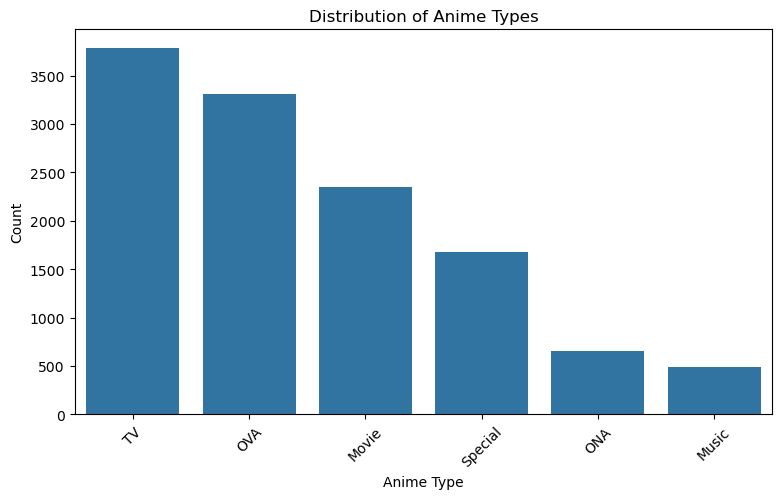

In [5]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x='type',
    order=df['type'].value_counts().index
)

plt.title("Distribution of Anime Types")
plt.xlabel("Anime Type")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.show()

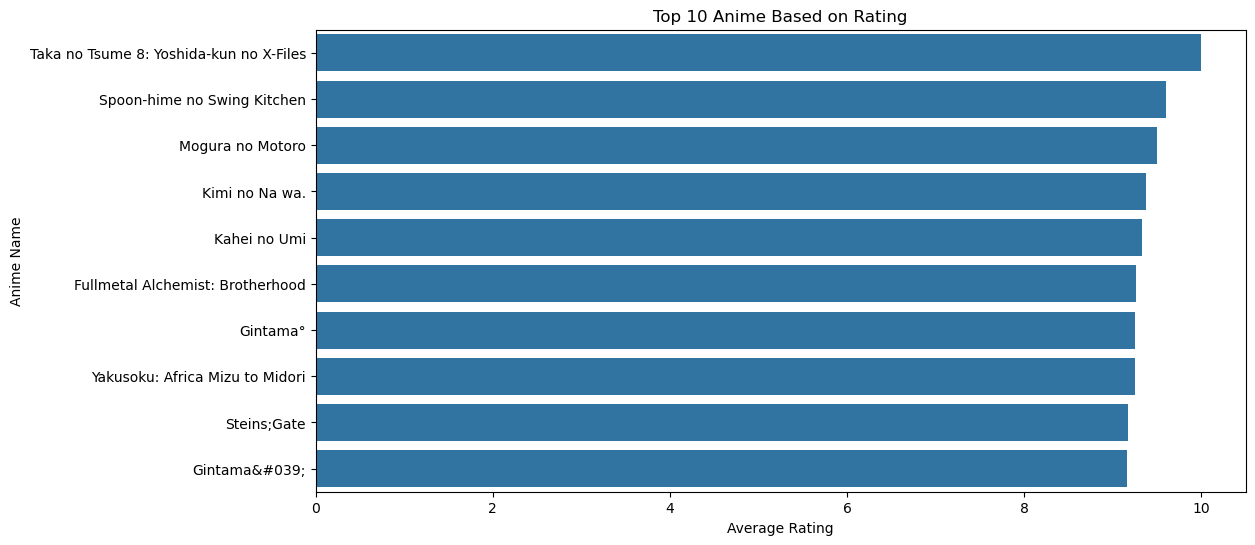

In [6]:
top_anime = df.sort_values(
    by='rating',
    ascending=False
).head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_anime,
    x='rating',
    y='name'
)

plt.title("Top 10 Anime Based on Rating")
plt.xlabel("Average Rating")
plt.ylabel("Anime Name")
plt.show()

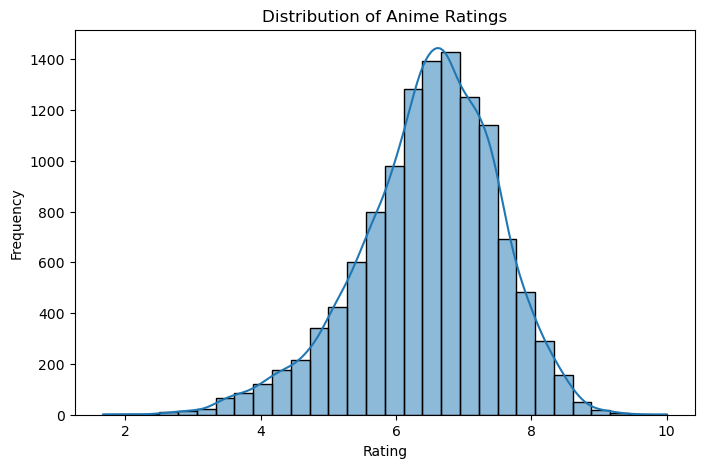

In [7]:
plt.figure(figsize=(8, 5))

sns.histplot(
    df['rating'].dropna(),
    bins=30,
    kde=True
)

plt.title("Distribution of Anime Ratings")
plt.xlabel("Rating")
plt.ylabel("Frequency")
plt.show()

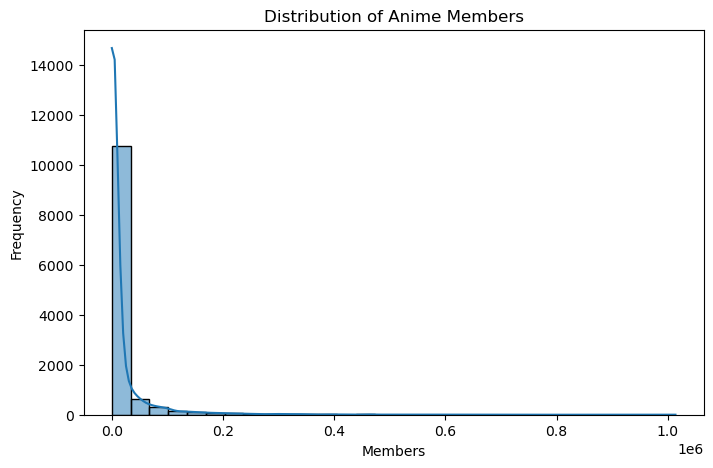

In [8]:
plt.figure(figsize=(8, 5))

sns.histplot(
    df['members'],
    bins=30,
    kde=True
)

plt.title("Distribution of Anime Members")
plt.xlabel("Members")
plt.ylabel("Frequency")
plt.show()

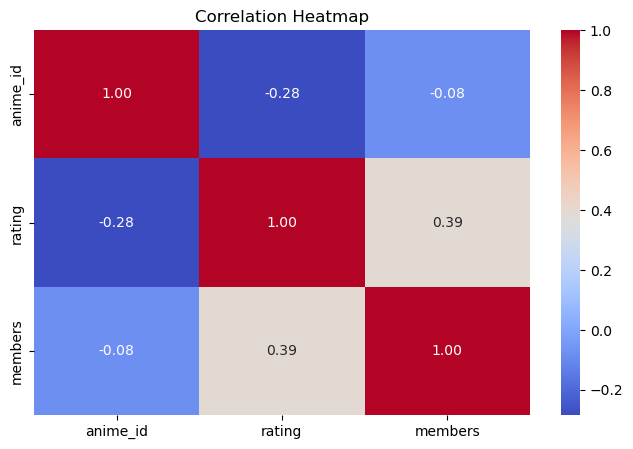

In [9]:
plt.figure(figsize=(8, 5))

numeric_df = df.select_dtypes(include=np.number)

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap")
plt.show()

Data Preprocessing

In [10]:
# Check missing values
print(df.isnull().sum())

# Fill missing genre values
df['genre'] = df['genre'].fillna('Unknown')

# Fill missing type values
df['type'] = df['type'].fillna('Unknown')

# Convert episodes into numeric format
df['episodes'] = pd.to_numeric(
    df['episodes'],
    errors='coerce'
)

# Fill missing episodes with median
df['episodes'] = df['episodes'].fillna(
    df['episodes'].median()
)

# Fill missing ratings with median
df['rating'] = df['rating'].fillna(
    df['rating'].median()
)

# Fill missing members with median
df['members'] = df['members'].fillna(
    df['members'].median()
)

print("\nMissing values after preprocessing:")
print(df.isnull().sum())

anime_id      0
name          0
genre        62
type         25
episodes      0
rating      230
members       0
dtype: int64

Missing values after preprocessing:
anime_id    0
name        0
genre       0
type        0
episodes    0
rating      0
members     0
dtype: int64


In [11]:
# Remove records with missing anime names
df = df.dropna(subset=['name'])

# Remove duplicate anime names
df = df.drop_duplicates(subset=['name'])

# Reset index
df = df.reset_index(drop=True)

print("Dataset Shape After Cleaning:", df.shape)

Dataset Shape After Cleaning: (12292, 7)


In [12]:
df['episodes'] = pd.to_numeric(
    df['episodes'],
    errors='coerce'
)

df['episodes'] = df['episodes'].fillna(
    df['episodes'].median()
)

In [13]:
display(df.head(10))

print("Total Records:", len(df))
print("Missing Values:", df.isnull().sum().sum())
print("Duplicate Records:", df.duplicated().sum())

,anime_id,name,genre,type,episodes,rating,members
0,32281,Kimi no Na wa.,"Drama, Romance, School, Supernatural",Movie,1.0,9.37,200630
1,5114,Fullmetal Alchemist: Brotherhood,"Action, Adventure, Drama, Fantasy, Magic, Mili...",TV,64.0,9.26,793665
2,28977,Gintama°,"Action, Comedy, Historical, Parody, Samurai, S...",TV,51.0,9.25,114262
3,9253,Steins;Gate,"Sci-Fi, Thriller",TV,24.0,9.17,673572
4,9969,Gintama&#039;,"Action, Comedy, Historical, Parody, Samurai, S...",TV,51.0,9.16,151266
5,32935,Haikyuu!!: Karasuno Koukou VS Shiratorizawa Ga...,"Comedy, Drama, School, Shounen, Sports",TV,10.0,9.15,93351
6,11061,Hunter x Hunter (2011),"Action, Adventure, Shounen, Super Power",TV,148.0,9.13,425855
7,820,Ginga Eiyuu Densetsu,"Drama, Military, Sci-Fi, Space",OVA,110.0,9.11,80679
8,15335,Gintama Movie: Kanketsu-hen - Yorozuya yo Eien...,"Action, Comedy, Historical, Parody, Samurai, S...",Movie,1.0,9.10,72534
9,15417,Gintama&#039;: Enchousen,"Action, Comedy, Historical, Parody, Samurai, S...",TV,13.0,9.11,81109


Total Records: 12292
Missing Values: 0
Duplicate Records: 0


In [14]:
# Initialize TF-IDF Vectorizer
tfidf = TfidfVectorizer(
    stop_words='english',
    token_pattern=r'(?u)\b\w+\b'
)

# Convert genres into numerical vectors
genre_matrix = tfidf.fit_transform(
    df['genre'].astype(str)
)

print("Genre Matrix Shape:", genre_matrix.shape)

Genre Matrix Shape: (12292, 47)


In [15]:
from sklearn.preprocessing import OneHotEncoder

# Initialize encoder
encoder = OneHotEncoder(handle_unknown='ignore')

# Convert type into numerical representation
type_matrix = encoder.fit_transform(
    df[['type']].astype(str)
)

print("Type Matrix Shape:", type_matrix.shape)

Type Matrix Shape: (12292, 7)


In [16]:
from sklearn.preprocessing import MinMaxScaler

# Copy numerical features
numerical_features = df[
    ['episodes', 'rating', 'members']
].copy()

# Log transformation for members
numerical_features['members'] = np.log1p(
    numerical_features['members']
)

# Initialize scaler
scaler = MinMaxScaler()

# Normalize numerical features
numerical_matrix = scaler.fit_transform(
    numerical_features
)

print("Numerical Matrix Shape:", numerical_matrix.shape)

Numerical Matrix Shape: (12292, 3)


Combine All Features

In [17]:
from scipy.sparse import hstack, csr_matrix

# Assign feature weights
genre_weight = 2.0
type_weight = 0.5
numerical_weight = 0.5

# Combine all feature matrices
feature_matrix = hstack([
    genre_matrix * genre_weight,
    type_matrix * type_weight,
    csr_matrix(numerical_matrix) * numerical_weight
]).tocsr()

print("Final Feature Matrix Shape:", feature_matrix.shape)

Final Feature Matrix Shape: (12292, 57)


Build the Anime Recommendation System

In [18]:
def recommend_anime(anime_name, top_n=10, threshold=0.0):

    # Find anime index
    matches = df.index[
        df['name'].str.casefold() == anime_name.casefold()
    ].tolist()

    if not matches:
        print("Anime not found in dataset!")
        return pd.DataFrame()

    anime_index = matches[0]

    # Calculate similarity against all anime
    similarity_scores = cosine_similarity(
        feature_matrix[anime_index],
        feature_matrix
    ).flatten()

    # Store similarity scores
    scores = pd.DataFrame({
        'Anime': df['name'],
        'Similarity Score': similarity_scores
    })

    # Remove selected anime
    scores = scores.drop(anime_index)

    # Apply similarity threshold
    scores = scores[
        scores['Similarity Score'] >= threshold
    ]

    # Sort by similarity score
    scores = scores.sort_values(
        by='Similarity Score',
        ascending=False
    )

    # Return top recommendations
    return scores.head(top_n).reset_index(drop=True)

Test the Recommendation System

In [19]:
# Recommend anime similar to Naruto
recommendations = recommend_anime(
    anime_name='Naruto',
    top_n=10
)

display(recommendations)

,Anime,Similarity Score
0,Naruto: Shippuuden,0.999593
1,Rekka no Honoo,0.951787
2,Dragon Ball Z,0.945153
3,Dragon Ball Kai,0.944279
4,Boruto: Naruto the Movie,0.944183
5,Naruto: Shippuuden Movie 4 - The Lost Tower,0.944179
6,Naruto: Shippuuden Movie 3 - Hi no Ishi wo Tsu...,0.944154
7,Dragon Ball Super,0.943784
8,Kurokami The Animation,0.943180
9,Dragon Ball Kai (2014),0.943167


Display Recommendations with Anime Details

In [20]:
def recommend_anime_details(anime_name, top_n=10, threshold=0.0):

    recommendations = recommend_anime(
        anime_name,
        top_n,
        threshold
    )

    if recommendations.empty:
        return recommendations

    # Add anime details
    result = recommendations.merge(
        df[['name', 'genre', 'type',
            'episodes', 'rating', 'members']],
        left_on='Anime',
        right_on='name',
        how='left'
    )

    result = result.drop(columns=['name'])

    return result

In [21]:
# Display detailed recommendations
display(
    recommend_anime_details(
        'Naruto',
        top_n=10
    )
)

,Anime,Similarity Score,genre,type,episodes,rating,members
0,Naruto: Shippuuden,0.999593,"Action, Comedy, Martial Arts, Shounen, Super P...",TV,2.0,7.94,533578
1,Rekka no Honoo,0.951787,"Action, Adventure, Martial Arts, Shounen, Supe...",TV,42.0,7.44,35258
2,Dragon Ball Z,0.945153,"Action, Adventure, Comedy, Fantasy, Martial Ar...",TV,291.0,8.32,375662
3,Dragon Ball Kai,0.944279,"Action, Adventure, Comedy, Fantasy, Martial Ar...",TV,97.0,7.95,116832
4,Boruto: Naruto the Movie,0.944183,"Action, Comedy, Martial Arts, Shounen, Super P...",Movie,1.0,8.03,74690
5,Naruto: Shippuuden Movie 4 - The Lost Tower,0.944179,"Action, Comedy, Martial Arts, Shounen, Super P...",Movie,1.0,7.53,84527
6,Naruto: Shippuuden Movie 3 - Hi no Ishi wo Tsu...,0.944154,"Action, Comedy, Martial Arts, Shounen, Super P...",Movie,1.0,7.50,83515
7,Dragon Ball Super,0.943784,"Action, Adventure, Comedy, Fantasy, Martial Ar...",TV,2.0,7.40,111443
8,Kurokami The Animation,0.943180,"Action, Martial Arts, Super Power",TV,23.0,7.29,72750
9,Dragon Ball Kai (2014),0.943167,"Action, Adventure, Comedy, Fantasy, Martial Ar...",TV,61.0,8.01,42666


Test Different Threshold Values

In [22]:
# Different threshold values
thresholds = [0.20, 0.40, 0.60, 0.80]

for threshold in thresholds:

    print("\nThreshold:", threshold)

    result = recommend_anime(
        anime_name='Naruto',
        top_n=10,
        threshold=threshold
    )

    print("Number of Recommendations:", len(result))

    display(result)


Threshold: 0.2
Number of Recommendations: 10


,Anime,Similarity Score
0,Naruto: Shippuuden,0.999593
1,Rekka no Honoo,0.951787
2,Dragon Ball Z,0.945153
3,Dragon Ball Kai,0.944279
4,Boruto: Naruto the Movie,0.944183
5,Naruto: Shippuuden Movie 4 - The Lost Tower,0.944179
6,Naruto: Shippuuden Movie 3 - Hi no Ishi wo Tsu...,0.944154
7,Dragon Ball Super,0.943784
8,Kurokami The Animation,0.943180
9,Dragon Ball Kai (2014),0.943167



Threshold: 0.4
Number of Recommendations: 10


,Anime,Similarity Score
0,Naruto: Shippuuden,0.999593
1,Rekka no Honoo,0.951787
2,Dragon Ball Z,0.945153
3,Dragon Ball Kai,0.944279
4,Boruto: Naruto the Movie,0.944183
5,Naruto: Shippuuden Movie 4 - The Lost Tower,0.944179
6,Naruto: Shippuuden Movie 3 - Hi no Ishi wo Tsu...,0.944154
7,Dragon Ball Super,0.943784
8,Kurokami The Animation,0.943180
9,Dragon Ball Kai (2014),0.943167



Threshold: 0.6
Number of Recommendations: 10


,Anime,Similarity Score
0,Naruto: Shippuuden,0.999593
1,Rekka no Honoo,0.951787
2,Dragon Ball Z,0.945153
3,Dragon Ball Kai,0.944279
4,Boruto: Naruto the Movie,0.944183
5,Naruto: Shippuuden Movie 4 - The Lost Tower,0.944179
6,Naruto: Shippuuden Movie 3 - Hi no Ishi wo Tsu...,0.944154
7,Dragon Ball Super,0.943784
8,Kurokami The Animation,0.943180
9,Dragon Ball Kai (2014),0.943167



Threshold: 0.8
Number of Recommendations: 10


,Anime,Similarity Score
0,Naruto: Shippuuden,0.999593
1,Rekka no Honoo,0.951787
2,Dragon Ball Z,0.945153
3,Dragon Ball Kai,0.944279
4,Boruto: Naruto the Movie,0.944183
5,Naruto: Shippuuden Movie 4 - The Lost Tower,0.944179
6,Naruto: Shippuuden Movie 3 - Hi no Ishi wo Tsu...,0.944154
7,Dragon Ball Super,0.943784
8,Kurokami The Animation,0.943180
9,Dragon Ball Kai (2014),0.943167


Compare Recommendation Counts

In [23]:
thresholds = np.arange(0.0, 1.0, 0.1)

recommendation_counts = []

for threshold in thresholds:

    result = recommend_anime(
        anime_name='Naruto',
        top_n=len(df),
        threshold=threshold
    )

    recommendation_counts.append(len(result))


# Create comparison DataFrame
threshold_df = pd.DataFrame({
    'Threshold': thresholds,
    'Recommendation Count': recommendation_counts
})

display(threshold_df)

,Threshold,Recommendation Count
0,0.0,12291
1,0.1,7307
2,0.2,2958
3,0.3,1054
4,0.4,679
5,0.5,536
6,0.6,285
7,0.7,111
8,0.8,60
9,0.9,22


Visualize Threshold Comparison

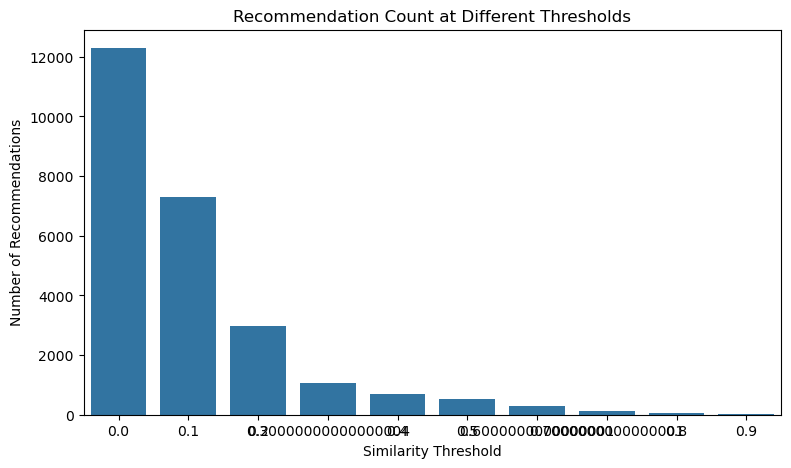

In [24]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=threshold_df,
    x='Threshold',
    y='Recommendation Count'
)

plt.title("Recommendation Count at Different Thresholds")
plt.xlabel("Similarity Threshold")
plt.ylabel("Number of Recommendations")

plt.show()

Visualize Recommended Anime

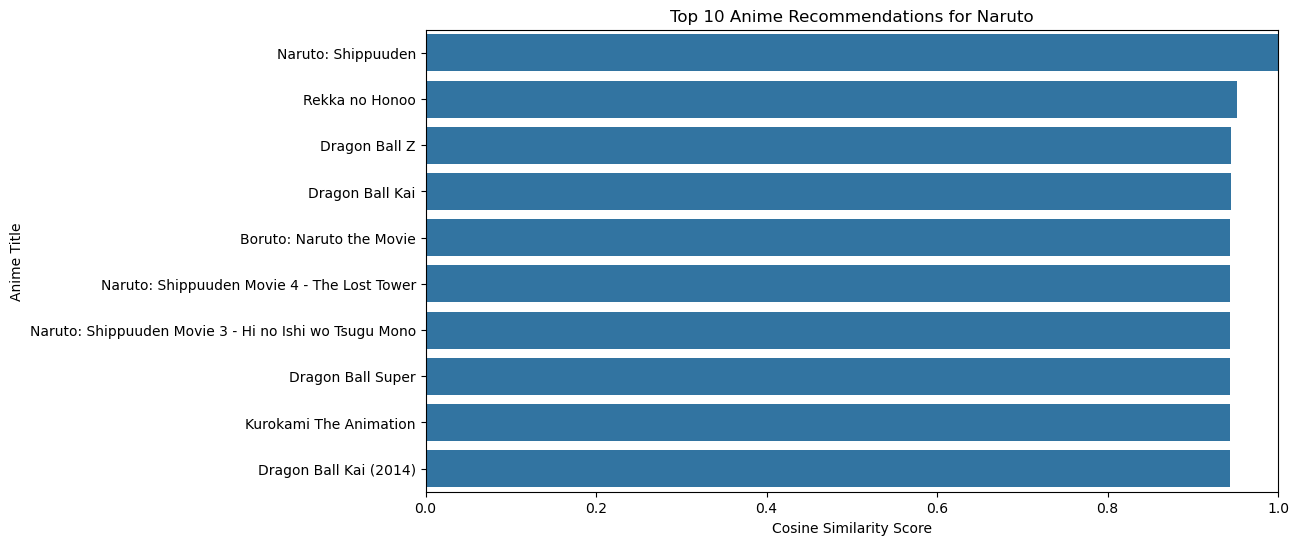

In [25]:
# Generate recommendations
recommendations = recommend_anime(
    'Naruto',
    top_n=10,
    threshold=0.0
)

# Plot recommendations
plt.figure(figsize=(11, 6))

sns.barplot(
    data=recommendations,
    x='Similarity Score',
    y='Anime'
)

plt.title("Top 10 Anime Recommendations for Naruto")
plt.xlabel("Cosine Similarity Score")
plt.ylabel("Anime Title")

plt.xlim(0, 1)
plt.show()

Compare Ratings of Recommended Anime

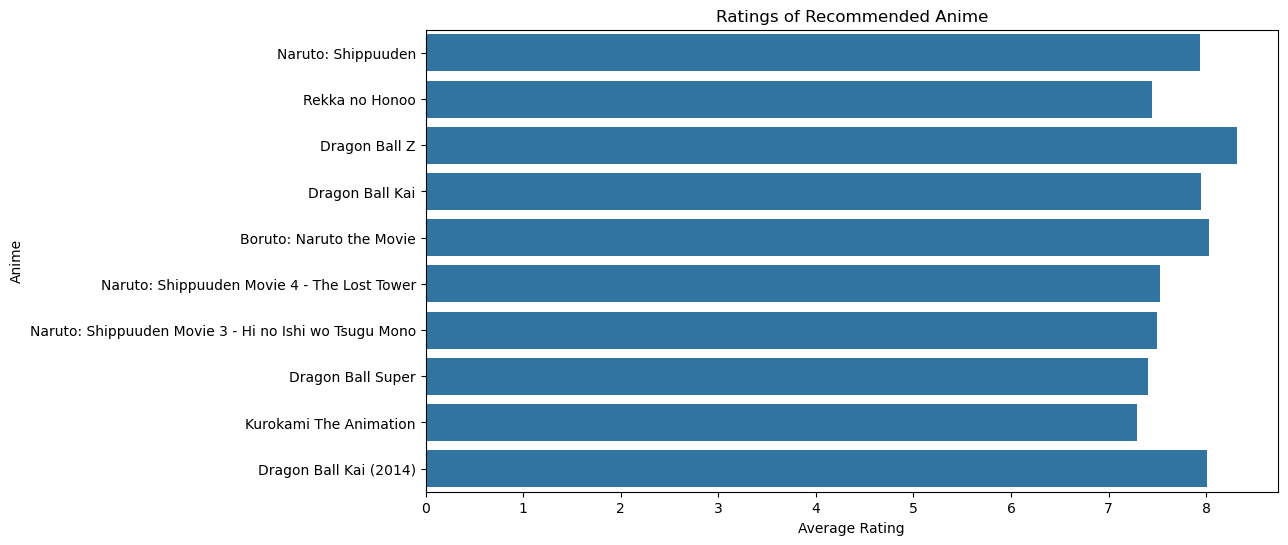

In [26]:
# Get recommendation details
recommended_details = recommend_anime_details(
    'Naruto',
    top_n=10
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=recommended_details,
    x='rating',
    y='Anime'
)

plt.title("Ratings of Recommended Anime")
plt.xlabel("Average Rating")
plt.ylabel("Anime")

plt.show()

Analyze the Performance of the Recommendation System

Similarity Score Analysis

In [27]:
# Get recommendations
result = recommend_anime(
    'Naruto',
    top_n=10
)

# Average similarity
print(
    "Average Similarity:",
    result['Similarity Score'].mean()
)

# Maximum similarity
print(
    "Maximum Similarity:",
    result['Similarity Score'].max()
)

# Minimum similarity
print(
    "Minimum Similarity:",
    result['Similarity Score'].min()
)

Average Similarity: 0.9503460061978727
Maximum Similarity: 0.9995928208461714
Minimum Similarity: 0.9431668211911374


Analyze Recommendation Diversity

In [28]:
# Get recommended anime genres
recommended_genres = recommended_details[
    ['Anime', 'genre']
]

display(recommended_genres)

,Anime,genre
0,Naruto: Shippuuden,"Action, Comedy, Martial Arts, Shounen, Super P..."
1,Rekka no Honoo,"Action, Adventure, Martial Arts, Shounen, Supe..."
2,Dragon Ball Z,"Action, Adventure, Comedy, Fantasy, Martial Ar..."
3,Dragon Ball Kai,"Action, Adventure, Comedy, Fantasy, Martial Ar..."
4,Boruto: Naruto the Movie,"Action, Comedy, Martial Arts, Shounen, Super P..."
5,Naruto: Shippuuden Movie 4 - The Lost Tower,"Action, Comedy, Martial Arts, Shounen, Super P..."
6,Naruto: Shippuuden Movie 3 - Hi no Ishi wo Tsu...,"Action, Comedy, Martial Arts, Shounen, Super P..."
7,Dragon Ball Super,"Action, Adventure, Comedy, Fantasy, Martial Ar..."
8,Kurokami The Animation,"Action, Martial Arts, Super Power"
9,Dragon Ball Kai (2014),"Action, Adventure, Comedy, Fantasy, Martial Ar..."
